In [19]:
import pandas as pd 
from pathlib import Path

print(Path.cwd())

data_train = pd.read_csv("../data/train.csv")
data_train.head()
data_train.shape
data_train.info()


c:\Users\danie\OneDrive\Desktop\Proyectos\Proyecto Credito Fraude\Kaggle-Fraud-Detection\notebooks
<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week     

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [21]:
data_train.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [26]:
proporcion = data_train["is_fraud"].value_counts(dropna=False)
print(proporcion)
porporcion_porcentaje = data_train["is_fraud"].value_counts(normalize=True) * 100
print(porporcion_porcentaje)

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64
is_fraud
0.0    98.330047
1.0     1.669953
Name: proportion, dtype: float64


Porcentaje de fraude = 1.66%
Porcentaje de No fraude = 98.33%

Clase minoritaria = fraude
Clase mayoritaria = nofraude

Acertar siempre en la clase mayoritaria no tendria sentido porque el objetivo es que nuestro modelo identifique los fraudes

##Calidad de los resultados

In [30]:
data_train.duplicated().sum()
data_train["id"].duplicated().sum()

np.int64(0)

In [31]:
data_train.drop(columns=["id"]).duplicated().sum()

np.int64(0)

In [32]:
data_train.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


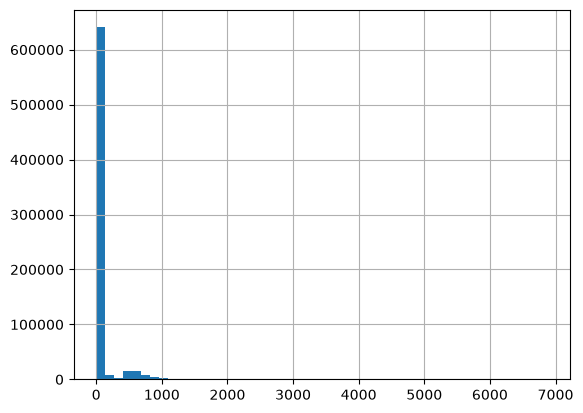

In [33]:
import matplotlib.pyplot as plt

data_train["amount_usd"].hist(bins=50)
plt.show()

<Axes: >

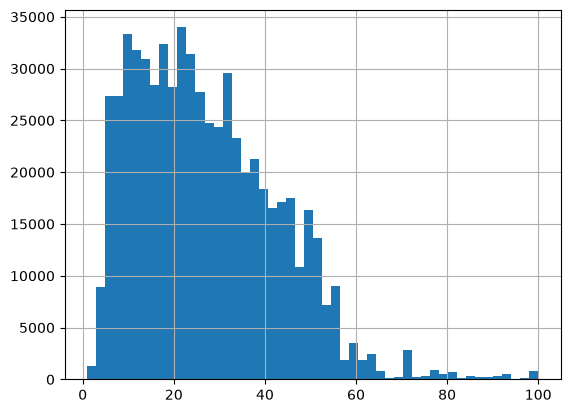

In [35]:
#Distribucion de montos hasta 100

data_train.loc[data_train["amount_usd"] <= 100, "amount_usd"].hist(bins=50)

In [36]:
data_train.groupby("is_fraud")["amount_usd"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0.0,688271.0,79.373189,204.165806,1.0,15.77,27.21,42.95,6872.69
1.0,11689.0,110.504532,255.808218,1.0,16.77,31.18,49.89,6078.29


In [42]:
rangos_montos = pd.cut(
    data_train["amount_usd"],
    bins=[0, 20, 50, 100, float("inf")],
    include_lowest=True
)
print(rangos_montos)

data_train.groupby(rangos_montos, observed=True)["is_fraud"].agg(["count", "sum", "mean"])

0          (50.0, 100.0]
1           (20.0, 50.0]
2         (-0.001, 20.0]
3           (20.0, 50.0]
4           (100.0, inf]
               ...      
699955      (100.0, inf]
699956      (20.0, 50.0]
699957      (20.0, 50.0]
699958    (-0.001, 20.0]
699959      (20.0, 50.0]
Name: amount_usd, Length: 699960, dtype: category
Categories (4, interval[float64, right]): [(-0.001, 20.0] < (20.0, 50.0] < (50.0, 100.0] < (100.0, inf]]


,count,sum,mean
amount_usd,,,
"(-0.001, 20.0]",239329,3631.0,0.015172
"(20.0, 50.0]",338891,5159.0,0.015223
"(50.0, 100.0]",53605,930.0,0.017349
"(100.0, inf]",68135,1969.0,0.028899


In [44]:
resumen_montos = (
    data_train.groupby(rangos_montos, observed=True)["is_fraud"]
    .agg(["count", "sum", "mean"])
)

resumen_montos["fraud_percentage"] = resumen_montos["mean"] * 100

resumen_montos

,count,sum,mean,fraud_percentage
amount_usd,,,,
"(-0.001, 20.0]",239329,3631.0,0.015172,1.517158
"(20.0, 50.0]",338891,5159.0,0.015223,1.522318
"(50.0, 100.0]",53605,930.0,0.017349,1.734913
"(100.0, inf]",68135,1969.0,0.028899,2.889851


In [51]:
canales = data_train["channel"]

resumen_channel = (
    data_train.groupby(canales, observed=True)["is_fraud"]
    .agg(["count", "sum", "mean"])
)

resumen_channel["fraud_percentage"] = resumen_channel["mean"] * 100

resumen_channel

,count,sum,mean,fraud_percentage
channel,,,,
ATM,30220,480.0,0.015884,1.588352
Contactless,105620,1641.0,0.015537,1.553683
In-App,83716,1367.0,0.016329,1.632902
Online,273939,4773.0,0.017424,1.742359
POS,206465,3428.0,0.016603,1.660330


In [52]:
origen_pago = data_train["is_foreign_transaction"]
resumen_origen_pago = (data_train.groupby(origen_pago, observed = True)["is_fraud"]).agg(["count", "sum", "mean"])
resumen_origen_pago["fraud_percentage"] =resumen_origen_pago["mean"] * 100

resumen_origen_pago

,count,sum,mean,fraud_percentage
is_foreign_transaction,,,,
False,687862,10168.0,0.014782,1.478203
True,12098,1521.0,0.125723,12.572326


In [65]:
fraude_dia = data_train["day_of_week"].value_counts().sort_index()
fraude_dia = data_train.groupby("day_of_week")["is_fraud"].agg(["count", "sum", "mean"])
fraude_dia["fraud_percentage"] = fraude_dia["mean"] * 100
fraude_dia

,count,sum,mean,fraud_percentage
day_of_week,,,,
0,100548,1591.0,0.015823,1.582329
1,102288,1694.0,0.016561,1.656108
2,101467,1697.0,0.016725,1.672465
3,97261,1595.0,0.016399,1.639917
4,102508,1718.0,0.016760,1.675967
5,95271,1600.0,0.016794,1.679420
6,100617,1794.0,0.017830,1.782999


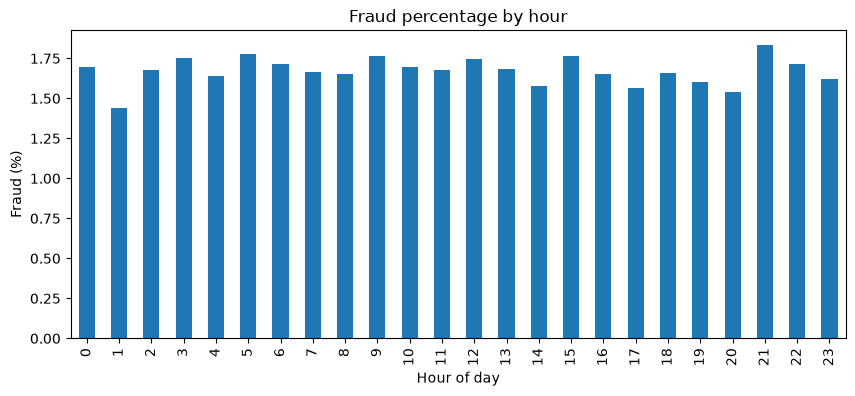

In [68]:
fraude_hora = data_train["time_of_day_hour"].value_counts().sort_index()
fraude_hora = data_train.groupby("time_of_day_hour")["is_fraud"].agg(["count", "sum", "mean"])
fraude_hora["fraud_percentage"] = fraude_hora["mean"] * 100
fraude_hora

fraude_hora["fraud_percentage"].plot(
    kind="bar",
    figsize=(10, 4)
)

plt.xlabel("Hour of day")
plt.ylabel("Fraud (%)")
plt.title("Fraud percentage by hour")
plt.ylim(bottom=0)
plt.show()